# 🧪 A/B Test — One-Page Checkout Redesign (Baku food-delivery app)
**Daily Data Analytics Project · Day 04**

## 1. Business question
A food-delivery app in Azerbaijan replaced its 3-step checkout (cart → address → payment) with a **one-page checkout**.
For 21 days (1–21 Sep 2026) new visitors were randomised 50/50 into **control** (old flow) and **treatment** (new flow).

Product wants to know:
1. Did the new checkout **increase conversion** and **revenue per user** — and by how much, with what certainty?
2. Did it hurt any **guardrail** (order cancellations, basket size)?
3. Does the effect hold for **every segment** (Android / iOS / web, new / returning)?
4. Was the test **trustworthy** (sample-ratio mismatch, contamination, novelty effect, enough power)?
5. **Ship or not?** What is the expected annual revenue impact?

Stack: pandas · SciPy (z-test, Welch t-test, χ²) · bootstrap · CUPED variance reduction · Holm correction · matplotlib.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE, GREEN, RED, GREY = "#2E6FBA", "#E8833A", "#3A9D5D", "#C8453B", "#8A8F98"
COL = {"control": GREY, "treatment": BLUE}
IMG = Path("images"); IMG.mkdir(exist_ok=True)
rng = np.random.default_rng(42)

raw = pd.read_csv("data/checkout_ab_test.csv", parse_dates=["assign_date"])
print(raw.shape)
raw.head()

(48420, 13)


,user_id,assign_date,group,device,user_type,city,pre_orders_30d,sessions,converted,orders,revenue_azn,cancelled,checkout_time_sec
0,853191,2026-09-18,control,android,returning,Baku,1,2,0,0,0.0000,0,NaN
1,145015,2026-09-20,treatment,android,returning,Baku,0,2,0,0,0.0000,0,NaN
2,632514,2026-09-20,control,android,new,Baku,0,3,0,0,0.0000,0,NaN
3,312258,2026-09-12,control,web,new,Baku,0,3,0,0,0.0000,0,NaN
4,361909,2026-09-06,treatment,web,new,Sumgait,0,5,0,0,0.0000,0,NaN


## 2. Data quality check

In [2]:
dq = pd.Series({
    "rows": len(raw),
    "unique users": raw.user_id.nunique(),
    "exact duplicate rows": raw.duplicated().sum(),
    "users in BOTH groups": (raw.groupby("user_id").group.nunique() > 1).sum(),
    "internal QA accounts (user_id < 100)": (raw.user_id < 100).sum(),
    "converters with missing revenue": (raw.converted.eq(1) & raw.revenue_azn.isna()).sum(),
})
dq.to_frame("count")

,count
rows,48420
unique users,48060
exact duplicate rows,220
users in BOTH groups,140
internal QA accounts (user_id < 100),60
converters with missing revenue,35


Cleaning rules (decided **before** looking at results):
- drop exact duplicate exposure rows (logging fired twice);
- drop users exposed to **both** variants — their outcome can't be attributed to one flow;
- drop internal QA/test accounts;
- impute missing revenue of converters with the **group median** order revenue (35 rows, <0.1% of users).

In [3]:
df = raw.drop_duplicates()
both = df.groupby("user_id").group.nunique()
df = df[~df.user_id.isin(both[both > 1].index)]
df = df[df.user_id >= 100].copy()
miss = df.converted.eq(1) & df.revenue_azn.isna()
med = df[df.converted.eq(1)].groupby("group").revenue_azn.median()
df.loc[miss, "revenue_azn"] = df.loc[miss, "group"].map(med)
assert df.user_id.is_unique
print(f"Clean users: {len(df):,} (removed {len(raw) - len(df):,} rows)")

Clean users: 47,860 (removed 560 rows)


### Sample Ratio Mismatch (SRM) check
If randomisation is 50/50, the group sizes should match that split. A χ² p-value < 0.001 would mean the
assignment or logging is broken and **no result can be trusted**.

In [4]:
n = df.group.value_counts().reindex(["control", "treatment"])
chi2, p_srm = stats.chisquare(n, [len(df) / 2] * 2)
raw_n = raw.group.value_counts().reindex(["control", "treatment"])
_, p_srm_raw = stats.chisquare(raw_n, [len(raw) / 2] * 2)
print(n.to_dict(), f"-> share treatment {n.treatment / n.sum():.2%}, SRM p = {p_srm:.3f}")
print(f"Before cleaning (QA accounts + duplicates included): SRM p = {p_srm_raw:.3f}")

{'control': 24015, 'treatment': 23845} -> share treatment 49.82%, SRM p = 0.437
Before cleaning (QA accounts + duplicates included): SRM p = 0.716


Covariate balance — pre-experiment behaviour and segment mix should be the same in both groups:

In [5]:
bal = pd.concat([
    df.groupby("group")[["pre_orders_30d", "sessions"]].mean().T,
    pd.crosstab(df.device, df.group, normalize="columns"),
    pd.crosstab(df.user_type, df.group, normalize="columns"),
])
bal["diff"] = bal.treatment - bal.control
bal

group,control,treatment,diff
pre_orders_30d,1.2422,1.2239,-0.0184
sessions,2.9333,2.9271,-0.0062
android,0.5187,0.5201,0.0014
ios,0.3113,0.3149,0.0036
web,0.1700,0.1650,-0.0050
new,0.3781,0.3804,0.0023
returning,0.6219,0.6196,-0.0023


## 3. Primary KPIs by group

In [6]:
conv = df[df.converted == 1]
kpi = df.groupby("group").agg(
    users=("user_id", "size"),
    converters=("converted", "sum"),
    conversion_rate=("converted", "mean"),
    revenue_azn=("revenue_azn", "sum"),
    revenue_per_user=("revenue_azn", "mean"),
).join(conv.groupby("group").agg(
    avg_order_revenue=("revenue_azn", "mean"),
    cancel_rate=("cancelled", "mean"),
    median_checkout_sec=("checkout_time_sec", "median"),
)).T
kpi["rel_lift_%"] = (kpi.treatment / kpi.control - 1) * 100
kpi

group,control,treatment,rel_lift_%
users,"24,015.0000","23,845.0000",-0.7079
converters,"2,243.0000","2,457.0000",9.5408
conversion_rate,0.0934,0.1030,10.3218
revenue_azn,"75,907.9200","82,843.4900",9.1368
revenue_per_user,3.1609,3.4742,9.9149
avg_order_revenue,33.8421,33.7173,-0.3688
cancel_rate,0.0495,0.0501,1.1594
median_checkout_sec,83.5000,63.2000,-24.3114


## 4. Statistical tests
### 4.1 Conversion — two-proportion z-test

In [7]:
def prop_test(x_c, n_c, x_t, n_t, alpha=0.05):
    p_c, p_t = x_c / n_c, x_t / n_t
    p_pool = (x_c + x_t) / (n_c + n_t)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_c + 1 / n_t))
    z = (p_t - p_c) / se_pool
    p = 2 * stats.norm.sf(abs(z))
    se = np.sqrt(p_c * (1 - p_c) / n_c + p_t * (1 - p_t) / n_t)
    zc = stats.norm.ppf(1 - alpha / 2)
    return dict(control=p_c, treatment=p_t, abs_diff=p_t - p_c, ci_low=p_t - p_c - zc * se,
                ci_high=p_t - p_c + zc * se, rel_lift=(p_t / p_c - 1), z=z, p_value=p)

g = df.groupby("group").converted.agg(["sum", "size"])
cr = prop_test(g.loc["control", "sum"], g.loc["control", "size"], g.loc["treatment", "sum"], g.loc["treatment", "size"])
pd.Series(cr).to_frame("conversion")

,conversion
control,0.0934
treatment,0.1030
abs_diff,0.0096
ci_low,0.0043
ci_high,0.0150
rel_lift,0.1032
z,3.5435
p_value,0.0004


### 4.2 Revenue per user — Welch t-test + bootstrap CI
Revenue per user is heavily skewed (≈89% zeros + long right tail), so the t-test result is confirmed with a
non-parametric **bootstrap** (5,000 resamples).

In [8]:
rc = df.loc[df.group == "control", "revenue_azn"].to_numpy()
rt = df.loc[df.group == "treatment", "revenue_azn"].to_numpy()
t_stat, p_rpu = stats.ttest_ind(rt, rc, equal_var=False)

B = 5000
boot = np.array([rng.choice(rt, rt.size).mean() - rng.choice(rc, rc.size).mean() for _ in range(B)])
rpu = dict(control=rc.mean(), treatment=rt.mean(), abs_diff=rt.mean() - rc.mean(),
           boot_ci_low=np.percentile(boot, 2.5), boot_ci_high=np.percentile(boot, 97.5),
           rel_lift=rt.mean() / rc.mean() - 1, t=t_stat, p_value=p_rpu)
pd.Series(rpu).to_frame("revenue per user (AZN)")

,revenue per user (AZN)
control,3.1609
treatment,3.4742
abs_diff,0.3134
boot_ci_low,0.0866
boot_ci_high,0.5296
rel_lift,0.0991
t,2.7709
p_value,0.0056


### 4.3 CUPED — variance reduction with pre-experiment data
CUPED adjusts each user's metric with a covariate measured **before** the test (orders in the previous 30 days):
$Y_{cuped} = Y - \theta (X - \bar X)$, $\theta = cov(X,Y)/var(X)$. Same expected effect, smaller variance → tighter CI.

In [9]:
def cuped(y, x):
    theta = np.cov(x, y)[0, 1] / np.var(x, ddof=1)
    return y - theta * (x - x.mean()), theta

res = []
for metric in ["converted", "revenue_azn"]:
    y_adj, theta = cuped(df[metric].to_numpy(float), df.pre_orders_30d.to_numpy(float))
    d = df.assign(y_adj=y_adj)
    for label, col in [("raw", metric), ("CUPED", "y_adj")]:
        a = d.loc[d.group == "control", col]; b = d.loc[d.group == "treatment", col]
        diff = b.mean() - a.mean()
        se = np.sqrt(a.var() / a.size + b.var() / b.size)
        res.append(dict(metric=metric, method=label, diff=diff, ci_low=diff - 1.96 * se,
                        ci_high=diff + 1.96 * se, se=se, p_value=2 * stats.norm.sf(abs(diff / se))))
cup = pd.DataFrame(res)
cup["variance_reduction_%"] = (1 - (cup.se / cup.groupby("metric").se.transform("first")) ** 2) * 100
cup

,metric,method,diff,ci_low,ci_high,se,p_value,variance_reduction_%
0,converted,raw,0.0096,0.0043,0.0150,0.0027,0.0004,0.0000
1,converted,CUPED,0.0107,0.0057,0.0157,0.0026,0.0000,11.1216
2,revenue_azn,raw,0.3134,0.0917,0.5351,0.1131,0.0056,0.0000
3,revenue_azn,CUPED,0.3510,0.1388,0.5632,0.1083,0.0012,8.3550


### 4.4 Guardrail metrics
The redesign must **not** materially hurt order quality. Guardrails: cancellation rate (non-inferiority margin +1 pp)
and average order revenue among converters.

In [10]:
ca = conv.groupby("group").cancelled.agg(["sum", "size"])
canc = prop_test(ca.loc["control", "sum"], ca.loc["control", "size"], ca.loc["treatment", "sum"], ca.loc["treatment", "size"])
aov_c = conv.loc[conv.group == "control", "revenue_azn"]; aov_t = conv.loc[conv.group == "treatment", "revenue_azn"]
_, p_aov = stats.ttest_ind(aov_t, aov_c, equal_var=False)
_, p_time = stats.mannwhitneyu(conv.loc[conv.group == "treatment", "checkout_time_sec"],
                               conv.loc[conv.group == "control", "checkout_time_sec"])
guard = pd.DataFrame([
    ["Cancellation rate", canc["control"], canc["treatment"], canc["abs_diff"], canc["p_value"],
     "PASS" if canc["ci_high"] < 0.01 else ("FAIL" if canc["p_value"] < 0.05 and canc["abs_diff"] > 0
                                           else "NO HARM DETECTED (CI wider than margin)")],
    ["Avg order revenue (AZN)", aov_c.mean(), aov_t.mean(), aov_t.mean() - aov_c.mean(), p_aov,
     "PASS" if aov_t.mean() / aov_c.mean() - 1 > -0.03 else "FAIL"],
    ["Median checkout time (s)", conv.loc[conv.group == "control", "checkout_time_sec"].median(),
     conv.loc[conv.group == "treatment", "checkout_time_sec"].median(), np.nan, p_time, "IMPROVED"],
], columns=["guardrail", "control", "treatment", "diff", "p_value", "status"])
print(f"Cancellation diff 95% CI: [{canc['ci_low']*100:+.2f}, {canc['ci_high']*100:+.2f}] pp (margin +1 pp)")
guard

Cancellation diff 95% CI: [-1.19, +1.30] pp (margin +1 pp)


,guardrail,control,treatment,diff,p_value,status
0,Cancellation rate,0.0495,0.0501,0.0006,0.9280,NO HARM DETECTED (CI wider than margin)
1,Avg order revenue (AZN),33.8421,33.7173,-0.1248,0.8525,PASS
2,Median checkout time (s),83.5000,63.2000,NaN,0.0000,IMPROVED


## 5. EDA — visualising the result

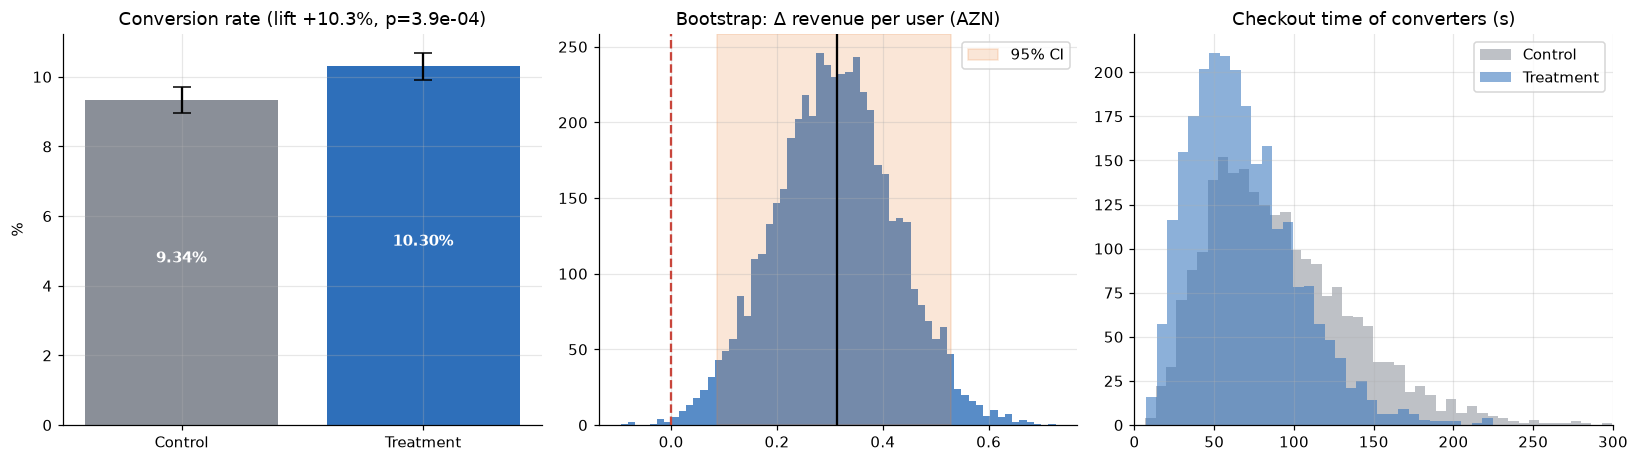

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ax = axes[0]
vals = [cr["control"] * 100, cr["treatment"] * 100]
err = [1.96 * np.sqrt(v / 100 * (1 - v / 100) / g.loc[k, "size"]) * 100 for v, k in zip(vals, ["control", "treatment"])]
ax.bar(["Control", "Treatment"], vals, yerr=err, capsize=6, color=[GREY, BLUE])
for i, v in enumerate(vals): ax.text(i, v / 2, f"{v:.2f}%", ha="center", color="white", fontweight="bold")
ax.set_title(f"Conversion rate (lift {cr['rel_lift']*100:+.1f}%, p={cr['p_value']:.1e})"); ax.set_ylabel("%")

ax = axes[1]
ax.hist(boot, bins=60, color=BLUE, alpha=0.8)
ax.axvline(0, color=RED, ls="--"); ax.axvline(rpu["abs_diff"], color="black")
ax.axvspan(rpu["boot_ci_low"], rpu["boot_ci_high"], color=ORANGE, alpha=0.2, label="95% CI")
ax.set_title("Bootstrap: Δ revenue per user (AZN)"); ax.legend()

ax = axes[2]
for grp in ["control", "treatment"]:
    ax.hist(conv.loc[conv.group == grp, "checkout_time_sec"], bins=50, alpha=0.55, color=COL[grp], label=grp.title())
ax.set_title("Checkout time of converters (s)"); ax.set_xlim(0, 300); ax.legend()
plt.tight_layout(); plt.savefig(IMG / "primary_results.png", bbox_inches="tight"); plt.show()

### Novelty check — does the lift fade over time?
Daily lift by **assignment date** plus the cumulative lift. A big early effect that shrinks is a sign of novelty;
the decision should rest on the stable (later) period.

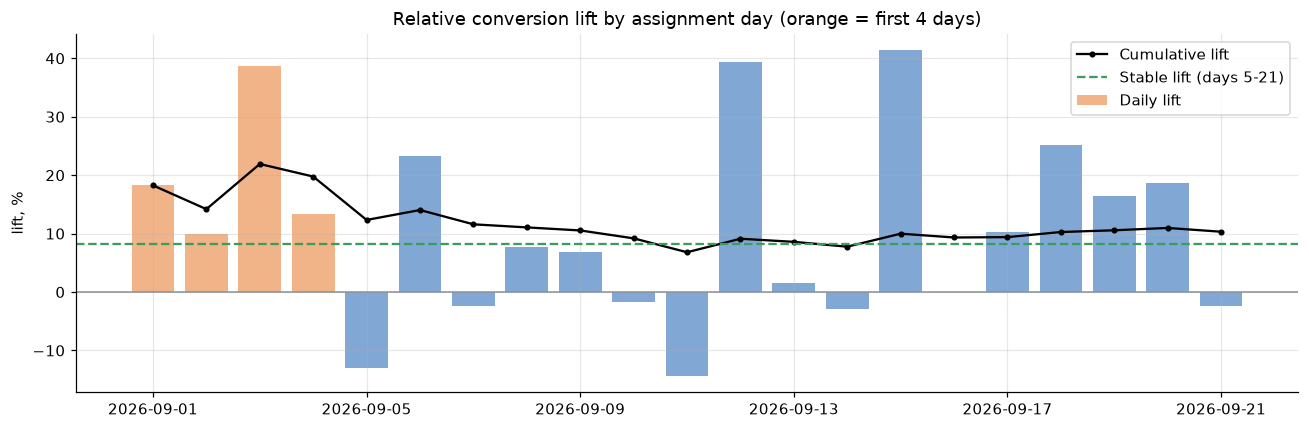

,control,treatment,rel_lift,p_value
Days 1-4,0.0882,0.1056,0.1976,0.0048
Days 5-21,0.0946,0.1024,0.0824,0.0101


In [12]:
daily = df.groupby(["assign_date", "group"]).converted.agg(["sum", "size"]).unstack()
daily_cr = daily["sum"] / daily["size"]
daily_lift = (daily_cr.treatment / daily_cr.control - 1) * 100
cum = daily["sum"].cumsum() / daily["size"].cumsum()
cum_lift = (cum.treatment / cum.control - 1) * 100

early = df.assign_date < "2026-09-05"
nov = pd.DataFrame({
    period: pd.Series(prop_test(*[x for k in ["control", "treatment"]
                                  for x in sub[sub.group == k].converted.agg(["sum", "size"])]))
    for period, sub in [("Days 1-4", df[early]), ("Days 5-21", df[~early])]
}).T[["control", "treatment", "rel_lift", "p_value"]]

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(daily_lift.index, daily_lift, color=[ORANGE if d < pd.Timestamp("2026-09-05") else BLUE for d in daily_lift.index],
       alpha=0.6, label="Daily lift")
ax.plot(cum_lift.index, cum_lift, color="black", marker="o", ms=3, label="Cumulative lift")
ax.axhline(nov.loc["Days 5-21", "rel_lift"] * 100, color=GREEN, ls="--", label="Stable lift (days 5-21)")
ax.axhline(0, color=GREY, lw=1)
ax.set_title("Relative conversion lift by assignment day (orange = first 4 days)"); ax.set_ylabel("lift, %"); ax.legend()
plt.tight_layout(); plt.savefig(IMG / "lift_over_time.png", bbox_inches="tight"); plt.show()
nov

## 6. Segment analysis (heterogeneous effects)
Many segments = many tests → p-values are adjusted with the **Holm–Bonferroni** method to control false positives.

In [13]:
rows = []
for dim in ["device", "user_type", "city"]:
    for val, sub in df.groupby(dim):
        s = sub.groupby("group").converted.agg(["sum", "size"])
        r = prop_test(s.loc["control", "sum"], s.loc["control", "size"], s.loc["treatment", "sum"], s.loc["treatment", "size"])
        rows.append(dict(segment=f"{dim}={val}", users=len(sub), **{k: r[k] for k in
                    ["control", "treatment", "rel_lift", "abs_diff", "ci_low", "ci_high", "p_value"]}))
seg = pd.DataFrame(rows)
# Holm adjustment
order = seg.p_value.sort_values().index
m = len(seg); adj = np.maximum.accumulate([(m - i) * seg.p_value[j] for i, j in enumerate(order)])
seg.loc[order, "p_holm"] = np.minimum(adj, 1)
seg["significant"] = seg.p_holm < 0.05
seg

,segment,users,control,treatment,rel_lift,abs_diff,ci_low,ci_high,p_value,p_holm,significant
0,device=android,24857,0.0948,0.1066,0.1244,0.0118,0.0043,0.0193,0.0020,0.0141,True
1,device=ios,14985,0.1046,0.1133,0.0835,0.0087,-0.0012,0.0187,0.0864,0.1728,False
2,device=web,8018,0.0686,0.0722,0.0524,0.0036,-0.0076,0.0148,0.5291,0.5291,False
3,user_type=new,18150,0.0296,0.0381,0.2877,0.0085,0.0033,0.0138,0.0015,0.0121,True
4,user_type=returning,29710,0.1322,0.1429,0.0810,0.0107,0.0029,0.0185,0.0074,0.0443,True
5,city=Baku,37388,0.0956,0.1033,0.0813,0.0078,0.0017,0.0138,0.0120,0.0601,False
6,city=Ganja,4223,0.0779,0.0971,0.2467,0.0192,0.0022,0.0363,0.0272,0.1087,False
7,city=Sumgait,6249,0.0908,0.1053,0.1599,0.0145,-0.0002,0.0293,0.0536,0.1608,False


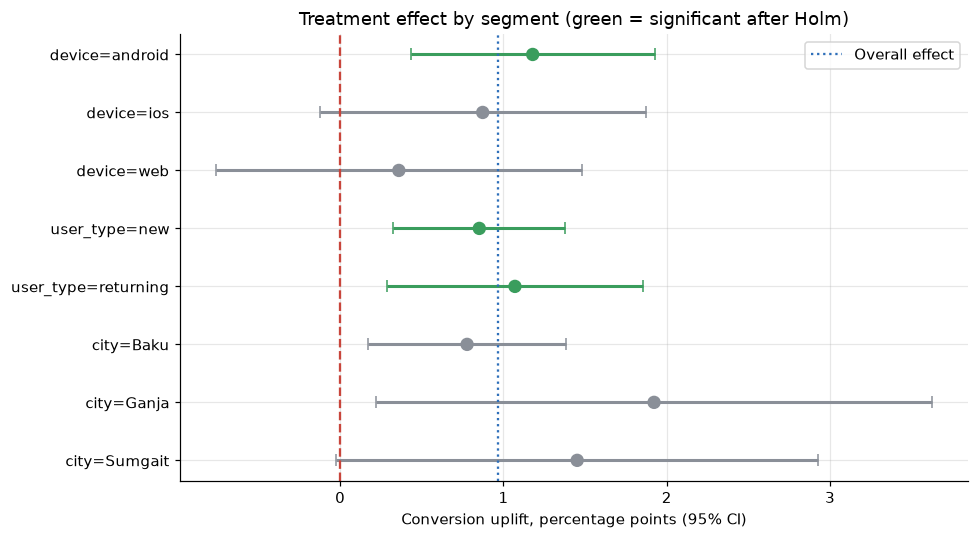

In [14]:
s = seg.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
colors = [GREEN if sig else GREY for sig in s.significant]
for (_, r), c in zip(s.iterrows(), colors):
    ax.errorbar(r.abs_diff * 100, r.segment, xerr=[[(r.abs_diff - r.ci_low) * 100], [(r.ci_high - r.abs_diff) * 100]],
                fmt="none", ecolor=c, elinewidth=2, capsize=4)
ax.scatter(s.abs_diff * 100, s.segment, c=colors, s=60, zorder=3)
ax.axvline(0, color=RED, ls="--"); ax.axvline(cr["abs_diff"] * 100, color=BLUE, ls=":", label="Overall effect")
ax.set_xlabel("Conversion uplift, percentage points (95% CI)")
ax.set_title("Treatment effect by segment (green = significant after Holm)"); ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig(IMG / "segment_effects.png", bbox_inches="tight"); plt.show()

## 7. Power & business impact
Was 21 days enough? Minimum detectable effect (MDE) at α = 0.05, power = 80% for the achieved sample size,
and the sample size that would be needed to detect a +5% relative lift.

In [15]:
za, zb = stats.norm.ppf(0.975), stats.norm.ppf(0.80)
p0 = cr["control"]; n_per = len(df) / 2
mde_abs = (za + zb) * np.sqrt(2 * p0 * (1 - p0) / n_per)
need_5 = (za + zb) ** 2 * 2 * p0 * (1 - p0) / (p0 * 0.05) ** 2
achieved_power = stats.norm.cdf(abs(cr["abs_diff"]) / np.sqrt(2 * p0 * (1 - p0) / n_per) - za)

# Business impact: traffic in the test ~ 1/21 of 3 weeks of new visitors; scale to a year
users_per_year = len(df) / 21 * 365
rpu_low, rpu_mid = rpu["boot_ci_low"], rpu["abs_diff"]
stable_rel = nov.loc["Days 5-21", "rel_lift"] / cr["rel_lift"]          # novelty haircut
impact = pd.Series({
    "MDE (abs, pp)": mde_abs * 100,
    "MDE (relative, %)": mde_abs / p0 * 100,
    "Users/arm needed for +5% rel. lift": need_5,
    "Achieved power for observed effect": achieved_power,
    "New users per year (est.)": users_per_year,
    "Extra revenue / year, AZN (point)": users_per_year * rpu_mid,
    "Extra revenue / year, AZN (novelty-adjusted)": users_per_year * rpu_mid * stable_rel,
    "Extra revenue / year, AZN (CI low)": users_per_year * rpu_low,
})
impact.to_frame("value")

,value
"MDE (abs, pp)",0.7453
"MDE (relative, %)",7.9796
Users/arm needed for +5% rel. lift,"60,949.0181"
Achieved power for observed effect,0.9519
New users per year (est.),"831,852.3810"
"Extra revenue / year, AZN (point)","260,698.7776"
"Extra revenue / year, AZN (novelty-adjusted)","208,205.6025"
"Extra revenue / year, AZN (CI low)","72,027.6810"


## 8. Findings & recommendations

In [16]:
web = seg.set_index("segment").loc["device=web"]
summary = pd.DataFrame([
    ["Test is trustworthy", f"SRM p = {p_srm:.2f}; covariates balanced; {len(raw) - len(df)} bad rows removed",
     "Keep SRM + QA-account filters as an automated pre-check for every experiment"],
    ["Conversion up", f"{cr['control']*100:.2f}% → {cr['treatment']*100:.2f}% ({cr['rel_lift']*100:+.1f}%, p = {cr['p_value']:.1e})",
     "Ship the one-page checkout in the mobile apps (Android significant, iOS directionally positive)"],
    ["Revenue per user up", f"{rpu['control']:.2f} → {rpu['treatment']:.2f} AZN ({rpu['rel_lift']*100:+.1f}%), "
     f"95% CI [{rpu['boot_ci_low']:+.2f}, {rpu['boot_ci_high']:+.2f}]",
     f"≈ {impact['Extra revenue / year, AZN (novelty-adjusted)']/1e3:,.0f}K AZN/yr (novelty-adjusted)"],
    ["New users benefit most", f"New users {seg.set_index('segment').loc['user_type=new','rel_lift']*100:+.1f}% vs returning "
     f"{seg.set_index('segment').loc['user_type=returning','rel_lift']*100:+.1f}%",
     "Fewer steps remove first-order friction — feature the new flow in acquisition campaigns"],
    ["Novelty effect present", f"Lift days 1-4: {nov.loc['Days 1-4','rel_lift']*100:+.1f}% vs days 5-21: "
     f"{nov.loc['Days 5-21','rel_lift']*100:+.1f}%", "Plan on the stable lift; monitor 4 weeks post-launch"],
    ["Web shows no clear win", f"Web lift {web.rel_lift*100:+.1f}%, Holm p = {web.p_holm:.2f}",
     "Iterate on web (address autocomplete, guest checkout) before rolling out"],
    ["No guardrail harm detected", f"Cancellation Δ {canc['abs_diff']*100:+.2f} pp (p = {canc['p_value']:.2f}, CI upper "
     f"{canc['ci_high']*100:+.2f} pp); AOV Δ {aov_t.mean()-aov_c.mean():+.2f} AZN; checkout {guard.loc[2,'control']:.0f}s → {guard.loc[2,'treatment']:.0f}s",
     "Cancellation test is underpowered for a 1 pp margin → monitor it weekly after launch with a rollback trigger"],
    ["CUPED tightens results", f"Variance −{cup.loc[(cup.metric=='converted') & (cup.method=='CUPED'),'variance_reduction_%'].iloc[0]:.0f}% "
     "for conversion with pre-period orders", "Use CUPED by default → shorter tests with the same power"],
], columns=["Finding", "Evidence", "Recommendation"])
summary.style.hide(axis="index").set_properties(**{"text-align": "left"})

Finding,Evidence,Recommendation
Test is trustworthy,SRM p = 0.44; covariates balanced; 560 bad rows removed,Keep SRM + QA-account filters as an automated pre-check for every experiment
Conversion up,"9.34% → 10.30% (+10.3%, p = 3.9e-04)","Ship the one-page checkout in the mobile apps (Android significant, iOS directionally positive)"
Revenue per user up,"3.16 → 3.47 AZN (+9.9%), 95% CI [+0.09, +0.53]",≈ 208K AZN/yr (novelty-adjusted)
New users benefit most,New users +28.8% vs returning +8.1%,Fewer steps remove first-order friction — feature the new flow in acquisition campaigns
Novelty effect present,Lift days 1-4: +19.8% vs days 5-21: +8.2%,Plan on the stable lift; monitor 4 weeks post-launch
Web shows no clear win,"Web lift +5.2%, Holm p = 0.53","Iterate on web (address autocomplete, guest checkout) before rolling out"
No guardrail harm detected,"Cancellation Δ +0.06 pp (p = 0.93, CI upper +1.30 pp); AOV Δ -0.12 AZN; checkout 84s → 63s",Cancellation test is underpowered for a 1 pp margin → monitor it weekly after launch with a rollback trigger
CUPED tightens results,Variance −11% for conversion with pre-period orders,Use CUPED by default → shorter tests with the same power
